## Lab 8: Check the claims

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']

listings = pd.read_csv('data/listings_clean.csv', parse_dates=date_columns)

print(listings.shape)

(4574, 73)


### Claim 1: "A night in Stockholm costs 1,791."

Notes:
- The boudaries of "Stockholm" is not super-clear. There are a few definitions and I can not find anyone that fits the data with 100% accuracy.
- The data only handles Airbnb listings which is not the only way to rent accomodation.
- There are a lot of prices missing (1617 missing out of 4574)
- The number (1791) in the statement refers to the median value (all listings included)
- The mean value is 2328 (all listings)
- It is not clear that price is in SEK

- **Verdict:** Does not hold. There is a huge spread of possible prices (120 to 40000) even within this dataset, which does itself not represent all available accomodation in Stockholm. It is also not clear that the price is in SEK, or that it is possible to rent a listing for one night.
- **New sentence:** The median price on a Airbnb listing in Stockholm(with some excusions) is 1,791 SEK (2957). 35.5% of the listings have no price. The mean price for Entire home/apartments is 2678 SEK (2346) and for private room the mean price is 999 SEK (591). Excluding hotel rooms which are barely present in the dataset. *Number of listings in parenthesis

In [3]:
listings["price"].describe()

count     2957.000000
mean      2327.643382
std       2160.353619
min        120.000000
25%       1071.120000
50%       1791.000000
75%       3003.800000
max      40000.000000
Name: price, dtype: float64

In [27]:
print(listings["price"].isna().sum())
print(listings["price"].count())
print(listings["id"].count())

1617
2957
4574


In [26]:
print((listings["price"].isna().sum() / listings["id"].count()).round(2))

0.35


In [ ]:
no_price = listings["price"].isna()

listings.loc[no_price, "neighbourhood_cleansed"].value_counts()

neighbourhood_cleansed
Södermalms                431
Hägersten-Liljeholmens    180
Norrmalms                 168
Enskede-Årsta-Vantörs     156
Kungsholmens              148
Skarpnäcks                103
Östermalms                 97
Bromma                     90
Älvsjö                     67
Farsta                     64
Hässelby-Vällingby         41
Rinkeby-Tensta             29
Skärholmens                26
Spånga-Tensta              17
Name: count, dtype: int64

In [38]:
pd.crosstab(listings['price'].isna(), listings['availability_365'] == 0)

availability_365,False,True
price,,
False,2953,4
True,127,1490


In [50]:
listings["price"].isna().groupby(listings["room_type"]).sum()

room_type
Entire home/apt    1414
Hotel room            2
Private room        196
Shared room           5
Name: price, dtype: int64

In [42]:
(listings['price'].groupby(listings['room_type']).mean()).round(2)

room_type
Entire home/apt    2678.53
Hotel room          859.00
Private room        999.02
Shared room         406.31
Name: price, dtype: float64

In [44]:
(listings['price'].groupby(listings['room_type']).count())

room_type
Entire home/apt    2346
Hotel room            1
Private room        591
Shared room          19
Name: price, dtype: int64

In [57]:
(listings['minimum_nights'].groupby(listings['room_type']).mean().round(1))

room_type
Entire home/apt    6.0
Hotel room         1.0
Private room       8.0
Shared room        2.7
Name: minimum_nights, dtype: float64

In [58]:
listings['minimum_nights'].describe()

count    4570.00000
mean        6.35733
std        23.89701
min         1.00000
25%         1.00000
50%         2.00000
75%         4.00000
max       500.00000
Name: minimum_nights, dtype: float64

### Claim 2: "The listings with a perfect 5.00 rating are the best in Stockholm."

Notes:
- Since a big number of reviews naturally drags the aggregated number away from 5 just by share volume it is very likly that the exact opposite statement is true.

- **Verdict:** Does not hold. In fact, it is possible that the exact opposite is true: "The listings with a perfect 5.00 rating are not the best in Stockholm.". This is because the statement does not take into account that a larger number of reviews will naturally gravitate away from the endpoint (5), and a larger number of reviews are probably more trustwothy than a single 5. The use of the word "best" is also slightly dubious as it has to with personal preference. If we define "best" as having a perfect 5.00, the statment is true, but circular, if "best" is something else that would need to be defined if we want to use it for statistics.
- **New sentence:** 3/4 of the values are above 4.75 and the scope narrows as the reviews increase, the median value is 4.92. There are 1484 listings with 5.0, but of those only 10%(328) has more than 10 reviews and only 0.9%(14) have over 50 reviews. We cannot statisticly say what the "best" listings are but there is a good reason to take number of reviews into concideration as more reviews means more trustworthy numbers as the law of large numbers apply.

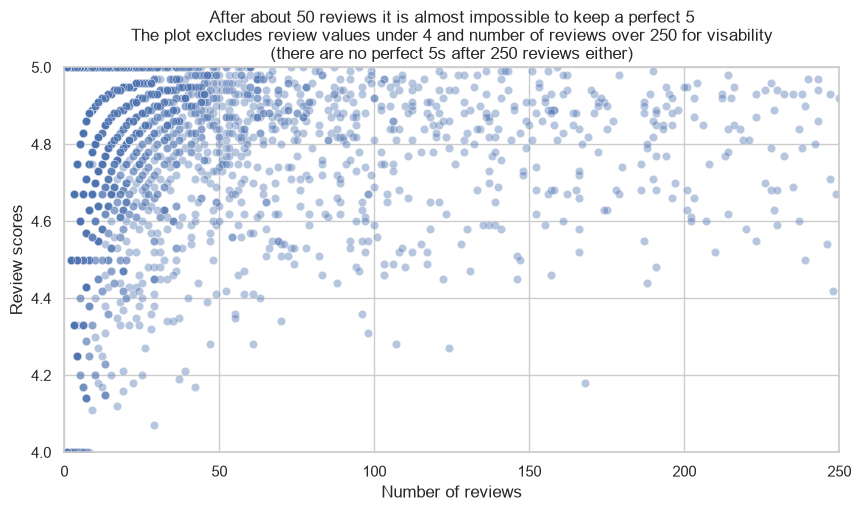

In [105]:

fig, ax = plt.subplots(figsize=(10, 5))

sns.scatterplot(data=listings, x="number_of_reviews", y="review_scores_rating", alpha=0.4, ax=ax)


ax.set_ylim(4, 5)
ax.set_xlim(0, 250)

ax.set_title("After about 50 reviews it is almost impossible to keep a perfect 5\nThe plot excludes review values under 4 and number of reviews over 250 for visability\n(there are no perfect 5s after 250 reviews either)")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Review scores")

plt.show()

In [89]:
listings['review_scores_rating'].describe()

count    3930.000000
mean        4.817692
std         0.317372
min         1.000000
25%         4.750000
50%         4.920000
75%         5.000000
max         5.000000
Name: review_scores_rating, dtype: float64

In [94]:
columns = ["review_scores_rating", "number_of_reviews"]

listings[columns].corr()["review_scores_rating"].round(2)

review_scores_rating    1.00
number_of_reviews      -0.04
Name: review_scores_rating, dtype: float64

In [110]:
print((listings["review_scores_rating"] == 5).sum())

1484


In [119]:
print(((listings["review_scores_rating"] == 5) & (listings["number_of_reviews"] > 10)).sum())

328


In [ ]:
print(((listings["review_scores_rating"] == 5) & (listings["number_of_reviews"] > 50)).sum())

14


In [127]:
print(((listings["review_scores_rating"] == 5) & (listings["number_of_reviews"] > 10)).sum() 
      / (listings["review_scores_rating"] == 5).sum())

0.2210242587601078


In [126]:
print(((listings["review_scores_rating"] == 5) & (listings["number_of_reviews"] > 50)).sum() 
      / (listings["review_scores_rating"] == 5).sum())

0.009433962264150943
